# Mission 1: Hydraulic Pump Leakage - XGBoost, Ridge OLR and SHAP

**Dataset:** [UCI Condition Monitoring of Hydraulic Systems](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems)  
**Question:** Can we classify leakage severity in **unseen operating configurations**?

This notebook contains the completed group-split experiment. Saved outputs, model comparisons and figures are retained.

In [1]:
# Imports
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn 
from sklearn.model_selection import train_test_split
import xgboost as xgb
from xgboost import XGBClassifier
import mord
import shap

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)



c:\Users\Admin\Desktop\צבא\הכשרה דאטא סיינס\4. DS Pipeline\ML - Leakage classification\DS Project---ML-classification-\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Constants
CE = 'CE' 
CP = 'CP' 
EPS1 = 'EPS1'
FS1 = 'FS1'
FS2 = 'FS2'
PROFILE = 'profile'
PS1 = 'PS1'
PS2 = 'PS2'
PS3 = 'PS3'
PS4 = 'PS4' 
PS5 = 'PS5'
PS6 = 'PS6'
SE = 'SE'
TS1 = 'TS1'
TS2 = 'TS2'
TS3 = 'TS3'
TS4 = 'TS4'
VS1 = 'VS1'

---
# Mission 1: Machine Learning with XGBoost and SHAP

**Target:** Pump leakage severity, 0 = none, 1 = weak, 2 = severe. Each observation is one 60-second cycle.

## 0. Problem understanding

Diagnose pump leakage under different cooler, valve and accumulator settings. We test whether the model generalizes to **new combinations** of these settings, not to new machines.

## 1. Data loading

Load the 17 sensor channels and operating-condition labels. Sensor rows and label rows describe the same cycles.

In [3]:
# Loading data from sensor files and profile.txt

def load_data(sensor_name):
    return pd.read_csv(
        f"data/{sensor_name}.txt",
        sep=r"\s+",
        header=None,
        dtype="float32"
    ).to_numpy()

raw_sensors = {}

# cooling efficiency sensor
raw_sensors[CE] = load_data(CE)

# cooling power sensor
raw_sensors[CP] = load_data(CP)

# motor power sensor
raw_sensors[EPS1] = load_data(EPS1)

# volume flow sensors
raw_sensors[FS1] = load_data(FS1)
raw_sensors[FS2] = load_data(FS2)

# profiles of each experiment
raw_profile = pd.read_csv(
    "data/profile.txt",
    sep=r"\s+",
    header=None
)

raw_profile.columns = [
    "cooler_condition",
    "valve_condition",
    "pump_leakage",
    "accumulator_pressure",
    "stable_flag"
]

# pressure motors
raw_sensors[PS1] = load_data(PS1)
raw_sensors[PS2] = load_data(PS2)
raw_sensors[PS3] = load_data(PS3)
raw_sensors[PS4] = load_data(PS4)
raw_sensors[PS5] = load_data(PS5)
raw_sensors[PS6] = load_data(PS6)

# efficiency factor
raw_sensors[SE] = load_data(SE)

# tempreture sensors
raw_sensors[TS1] = load_data(TS1)
raw_sensors[TS2] = load_data(TS2)
raw_sensors[TS3] = load_data(TS3)
raw_sensors[TS4] = load_data(TS4)

# vibration sensor
raw_sensors[VS1] = load_data(VS1)


In [4]:
# Sample rates for each sensor, come from description.txt
sample_rates = {
    PS1: 100,
    PS2: 100,
    PS3: 100,
    PS4: 100,
    PS5: 100,
    PS6: 100,
    EPS1: 100,
    FS1: 10,
    FS2: 10,
    TS1: 1,
    TS2: 1,
    TS3: 1,
    TS4: 1,
    VS1: 1,
    CE: 1,
    CP: 1,
    SE: 1
}

units = {
    PS1: 'bar',
    PS2: 'bar',
    PS3: 'bar',
    PS4: 'bar',
    PS5: 'bar',
    PS6: 'bar',
    EPS1: 'W',
    FS1: 'l/min',
    FS2: 'l/min',
    TS1: '°C',
    TS2: '°C',
    TS3: '°C',
    TS4: '°C',
    VS1: 'mm/s',  
    CE: '%',
    CP: 'kW',
    SE: '%'
}

## 2. Exploratory Data Analysis (EDA)

Examine class balance, stable/unstable cycles and sensor signals under matched conditions.

In [5]:
# Class balance pie chart
# mean time series with sd band
# sensors in experiment 0 (with boundries)
# leakage levels compared to stability 

# Calculate descriptive statistics for one sensor
def calculate_sensor_stats(sensor_name, data):

    data = np.asarray(data)

    # Combine measurements from all selected experiments
    values = data.flatten()

    # Quantiles
    q05, q25, q50, q75, q95 = np.quantile(
        values, [0.05, 0.25, 0.50, 0.75, 0.95]
    )

    return {
        "Sensor": sensor_name,
        "Sample Rate (Hz)": sample_rates[sensor_name],
        "Samples/Cycle": data.shape[1],
        "Cycles": data.shape[0],
        "Unit": units[sensor_name],
        "Mean": values.mean(),
        "Std": values.std(),
        "Min": values.min(),
        "Q05": q05,
        "Q25": q25,
        "Median": q50,
        "Q75": q75,
        "Q95": q95,
        "Max": values.max()
    }


# Display an EDA DataFrame with formatting and colors
def display_eda_table(df):

    stat_columns = [
        "Mean", "Std", "Min", "Q05", "Q25",
        "Median", "Q75", "Q95", "Max"
    ]

    styled = (
        df.style
        .format({col: "{:.2f}" for col in stat_columns})
        .set_table_styles([
            {
                "selector": "th.col_heading",
                "props": [
                    ("background-color", "#243b53"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("padding", "8px")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#edf2f7")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even) td, tbody tr:nth-child(even) th",
                "props": [
                    ("color", "#1f2937")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("padding", "6px 10px")
                ]
            }
        ])
    )

    # Color leakage levels when the column exists
    if "Leakage" in df.columns:

        leakage_colors = {
            0: "background-color: #b7e4c7; color: #14532d; font-weight: bold",
            1: "background-color: #ffe69c; color: #854d0e; font-weight: bold",
            2: "background-color: #f5b7b1; color: #991b1b; font-weight: bold"
        }

        styled = styled.map(
            lambda value: leakage_colors.get(value, ""),
            subset=["Leakage"]
        )

    display(styled)


# Create overall EDA table
overall_stats = []

for sensor_name, data in raw_sensors.items():

    stats = calculate_sensor_stats(sensor_name, data)
    overall_stats.append(stats)

eda_overall = pd.DataFrame(overall_stats)


# Display
print("OVERALL SENSOR STATISTICS")
display_eda_table(eda_overall)


OVERALL SENSOR STATISTICS


,Sensor,Sample Rate (Hz),Samples/Cycle,Cycles,Unit,Mean,Std,Min,Q05,Q25,Median,Q75,Q95,Max
0,CE,1,60,2205,%,31.30,11.58,17.04,18.74,20.13,27.30,46.62,47.44,48.78
1,CP,1,60,2205,kW,1.81,0.28,1.02,1.47,1.55,1.74,2.14,2.19,2.91
2,EPS1,100,6000,2205,W,2495.51,218.22,2097.80,2232.00,2338.80,2425.60,2614.60,2919.60,2995.20
3,FS1,10,600,2205,l/min,6.20,3.21,0.00,0.00,7.34,7.64,7.80,8.03,20.48
4,FS2,10,600,2205,l/min,9.65,0.45,8.76,8.92,9.21,9.69,10.15,10.19,10.45
5,PS1,100,6000,2205,bar,160.49,16.13,133.13,143.09,148.91,153.94,165.56,190.96,191.92
6,PS2,100,6000,2205,bar,109.38,48.10,0.00,0.00,118.54,125.70,130.41,164.66,167.77
7,PS3,100,6000,2205,bar,1.75,0.93,0.00,0.00,1.88,2.05,2.23,2.41,18.83
8,PS4,100,6000,2205,bar,2.60,4.30,0.00,0.00,0.00,0.00,3.98,10.15,10.27
9,PS5,100,6000,2205,bar,9.16,0.58,8.32,8.40,8.55,9.11,9.85,9.96,10.04


In [6]:
# Get pump leakage labels (0, 1, 2)
leakage_labels = raw_profile["pump_leakage"].to_numpy()

leakage_stats = []

for sensor_name, data in raw_sensors.items():

    data = np.asarray(data)

    # Ensure experiments and labels are aligned
    assert len(data) == len(leakage_labels), (
        f"Row mismatch for {sensor_name}. "
        "Check that all files were loaded with header=None."
    )

    for leakage_level in [0, 1, 2]:

        # Select experiments belonging to this leakage class
        mask = leakage_labels == leakage_level
        class_data = data[mask]

        # Calculate statistics
        stats = calculate_sensor_stats(sensor_name, class_data)
        stats["Leakage"] = leakage_level

        leakage_stats.append(stats)


# Create DataFrame
eda_by_leakage = pd.DataFrame(leakage_stats)

# Place Leakage column immediately after Sensor
columns = ["Sensor", "Leakage"] + [
    col for col in eda_by_leakage.columns
    if col not in ["Sensor", "Leakage"]
]

eda_by_leakage = eda_by_leakage[columns]


# Display
print("SENSOR STATISTICS BY PUMP LEAKAGE CONDITION")
display_eda_table(eda_by_leakage)

SENSOR STATISTICS BY PUMP LEAKAGE CONDITION


,Sensor,Leakage,Sample Rate (Hz),Samples/Cycle,Cycles,Unit,Mean,Std,Min,Q05,Q25,Median,Q75,Q95,Max
0,CE,0,1,60,1221,%,31.32,11.58,17.04,18.74,20.23,27.02,46.58,47.46,48.50
1,CE,1,1,60,492,%,31.22,11.63,18.09,18.71,19.66,27.47,46.64,47.40,48.47
2,CE,2,1,60,492,%,31.33,11.52,18.08,18.81,20.25,27.39,46.70,47.42,48.78
3,CP,0,1,60,1221,kW,1.81,0.29,1.02,1.45,1.56,1.74,2.14,2.19,2.91
4,CP,1,1,60,492,kW,1.80,0.27,1.42,1.48,1.53,1.74,2.14,2.18,2.23
5,CP,2,1,60,492,kW,1.80,0.26,1.42,1.48,1.57,1.73,2.13,2.18,2.25
6,EPS1,0,100,6000,1221,W,2467.50,205.35,2162.00,2231.60,2329.60,2409.80,2520.80,2905.80,2968.40
7,EPS1,1,100,6000,492,W,2519.31,226.63,2097.80,2233.60,2345.60,2464.00,2806.60,2907.20,2987.00
8,EPS1,2,100,6000,492,W,2541.23,229.80,2124.80,2250.00,2361.80,2488.80,2833.60,2923.80,2995.20
9,FS1,0,10,600,1221,l/min,6.60,3.03,0.00,0.00,7.66,7.76,7.86,8.06,20.48


In [7]:
# Conditions we want to keep identical
control_columns = [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]

# Consider stable experiments only
stable_data = raw_profile[
    raw_profile["stable_flag"] == 0
]

# Count experiments for each combination and leakage level
counts = (
    stable_data
    .groupby(control_columns + ["pump_leakage"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1, 2], fill_value=0)
)

# Find combinations containing all three leakage levels
matching_conditions = counts[
    (counts[[0, 1, 2]] > 0).all(axis=1)
]

print("Matching operating conditions found:", len(matching_conditions))

display(matching_conditions.head(10))

Matching operating conditions found: 48


pump_leakage                                            0   1   2
cooler_condition valve_condition accumulator_pressure            
3                73              90                    10  10  10
                                 100                   10  10  10
                                 115                   10  10  10
                                 130                   10  10  10
                 80              90                    10  10  10
                                 100                   10  10  10
                                 115                   10  10  10
                                 130                   10  10  10
                 90              90                    10  10  10
                                 100                   10  10  10

In [8]:
if matching_conditions.empty:

    print("No exact matching operating conditions found.")

else:

    # Prefer conditions with the most balanced number of experiments
    best_conditions = matching_conditions.min(axis=1).idxmax()

    matched_data = stable_data.copy()

    for column, value in zip(control_columns, best_conditions):
        matched_data = matched_data[
            matched_data[column] == value
        ]

    # Select one experiment for each leakage level
    selected_experiments = {}

    for level in [0, 1, 2]:

        candidates = matched_data[
            matched_data["pump_leakage"] == level
        ]

        selected_experiments[level] = int(
            candidates.sample(1, random_state=42).index[0]
        )

    print("Selected experiments:", selected_experiments)

    display(
        raw_profile.loc[list(selected_experiments.values())]
    )

Selected experiments: {0: 700, 1: 659, 2: 618}


,cooler_condition,valve_condition,pump_leakage,accumulator_pressure,stable_flag
700,3,73,0,90,0
659,3,73,1,90,0
618,3,73,2,90,0


In [9]:
# Compare the operating conditions of our selected experiments
experiment_ids = list(selected_experiments.values())

display(
    raw_profile.loc[experiment_ids, [
        "cooler_condition",
        "valve_condition",
        "pump_leakage",
        "accumulator_pressure",
        "stable_flag"
    ]]
)

,cooler_condition,valve_condition,pump_leakage,accumulator_pressure,stable_flag
700,3,73,0,90,0
659,3,73,1,90,0
618,3,73,2,90,0


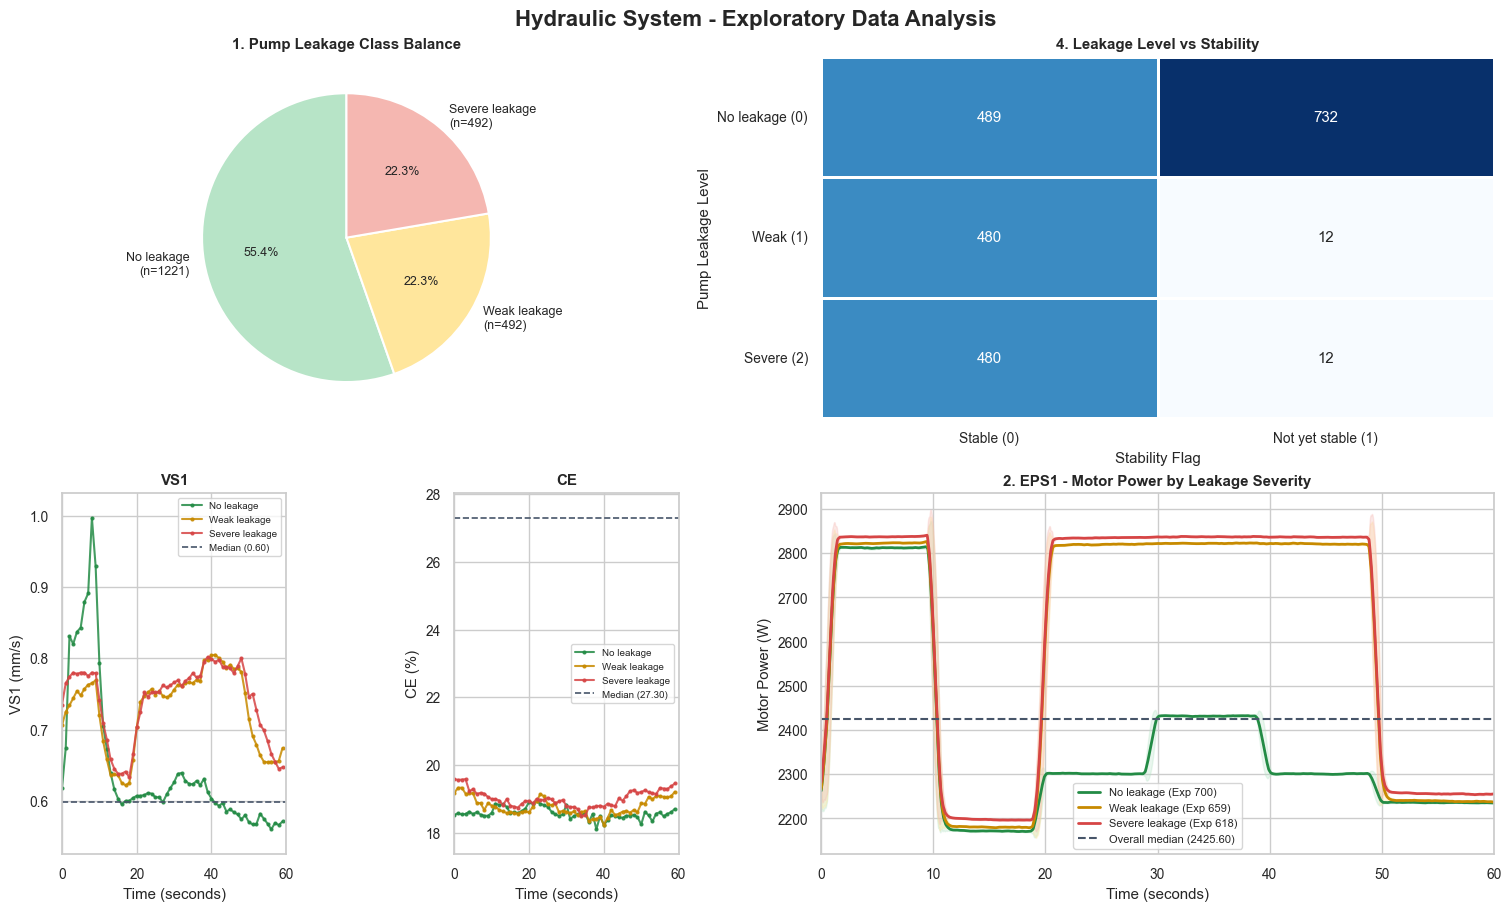

In [10]:

# ==================================================
# CONFIGURATION
# ==================================================

leakage_colors = {
    0: "#b7e4c7",
    1: "#ffe69c",
    2: "#f5b7b1"
}

line_colors = {
    0: "#238b45",
    1: "#c78a00",
    2: "#d64545"
}

leakage_names = {
    0: "No leakage",
    1: "Weak leakage",
    2: "Severe leakage"
}

# Matched experiments with identical operating conditions
selected_experiments = {
    0: 700,
    1: 659,
    2: 618
}


def sensor_median(sensor_name):
    return np.median(np.asarray(raw_sensors[sensor_name]))


# ==================================================
# FIGURE SETUP
# ==================================================

sns.set_theme(style="whitegrid", font_scale=0.9)

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    constrained_layout=True
)

fig.suptitle(
    "Hydraulic System - Exploratory Data Analysis",
    fontsize=16,
    fontweight="bold"
)


# ==================================================
# 1. LEAKAGE LEVEL BALANCE - TOP LEFT
# ==================================================

ax = axes[0, 0]

counts = (
    raw_profile["pump_leakage"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
)

labels = [
    f"{leakage_names[level]}\n(n={counts[level]})"
    for level in [0, 1, 2]
]

ax.pie(
    counts.values,
    labels=labels,
    colors=[leakage_colors[i] for i in [0, 1, 2]],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 1.5
    },
    textprops={"fontsize": 9}
)

ax.set_title(
    "1. Pump Leakage Class Balance",
    fontweight="bold"
)


# ==================================================
# 4. LEAKAGE VS STABILITY - TOP RIGHT
# ==================================================

ax = axes[0, 1]

stability_table = pd.crosstab(
    raw_profile["pump_leakage"].astype(int),
    raw_profile["stable_flag"].astype(int)
)

stability_table = stability_table.reindex(
    index=[0, 1, 2],
    columns=[0, 1],
    fill_value=0
)

sns.heatmap(
    stability_table,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    cbar=False,
    ax=ax
)

ax.set_title(
    "4. Leakage Level vs Stability",
    fontweight="bold"
)

ax.set_xlabel("Stability Flag")
ax.set_ylabel("Pump Leakage Level")

ax.set_xticklabels(
    ["Stable (0)", "Not yet stable (1)"],
    rotation=0
)

ax.set_yticklabels(
    ["No leakage (0)", "Weak (1)", "Severe (2)"],
    rotation=0
)


# ==================================================
# 3. VS1 AND CE - BOTTOM LEFT
# ==================================================

# Split bottom-left quadrant into two smaller plots
subplot_spec = axes[1, 0].get_subplotspec()
axes[1, 0].remove()

subgrid = subplot_spec.subgridspec(
    1, 2,
    wspace=0.15
)

sensor_axes = [
    fig.add_subplot(subgrid[0, 0]),
    fig.add_subplot(subgrid[0, 1])
]

comparison_sensors = [VS1, CE]

for ax, sensor_name in zip(
    sensor_axes,
    comparison_sensors
):

    sample_rate = sample_rates[sensor_name]
    median = sensor_median(sensor_name)

    for level, experiment_id in selected_experiments.items():

        signal = np.asarray(
            raw_sensors[sensor_name]
        )[experiment_id]

        time = np.arange(len(signal)) / sample_rate

        ax.plot(
            time,
            signal,
            color=line_colors[level],
            linewidth=1.5,
            alpha=0.85,
            marker="o",
            markersize=2,
            label=leakage_names[level]
        )

    # Overall median
    ax.axhline(
        median,
        color="#475569",
        linestyle="--",
        linewidth=1.2,
        label=f"Median ({median:.2f})"
    )

    ax.set_title(sensor_name, fontweight="bold")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel(f"{sensor_name} ({units[sensor_name]})")
    ax.set_xlim(0, 60)
    ax.margins(y=0.08)

    ax.legend(fontsize=7)


# ==================================================
# 2. EPS1 - ROLLING MEAN AND SD - BOTTOM RIGHT
# ==================================================

ax = axes[1, 1]

sensor_name = EPS1
sample_rate = sample_rates[sensor_name]

median = sensor_median(sensor_name)

for level, experiment_id in selected_experiments.items():

    signal = np.asarray(
        raw_sensors[sensor_name]
    )[experiment_id]

    time = np.arange(len(signal)) / sample_rate

    # Rolling statistics using a 1-second window
    rolling = pd.Series(signal).rolling(
        window=sample_rate,
        center=True,
        min_periods=2
    )

    rolling_mean = rolling.mean().to_numpy()
    rolling_std = rolling.std().fillna(0).to_numpy()

    ax.plot(
        time,
        rolling_mean,
        color=line_colors[level],
        linewidth=2,
        label=f"{leakage_names[level]} (Exp {experiment_id})"
    )

    ax.fill_between(
        time,
        rolling_mean - rolling_std,
        rolling_mean + rolling_std,
        color=leakage_colors[level],
        alpha=0.3
    )

# Overall median
ax.axhline(
    median,
    color="#475569",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall median ({median:.2f})"
)

ax.set_title(
    "2. EPS1 - Motor Power by Leakage Severity",
    fontweight="bold"
)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motor Power (W)")
ax.set_xlim(0, 60)
ax.margins(y=0.05)
ax.legend(fontsize=8)


# ==================================================
# DISPLAY
# ==================================================

plt.show()

## 3. Data cleaning

Keep stable cycles and remove nine randomly chosen stable no-leakage cycles to obtain 480 experiments per class.

In [11]:
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# 1. Identify stable experiments
stable_mask = raw_profile["stable_flag"].to_numpy() == 0

# 2. Find no-leakage experiments that are stable
healthy_positions = np.flatnonzero(
    stable_mask &
    (raw_profile["pump_leakage"].to_numpy() == 0)
)

# 3. Randomly select 9 no-leakage experiments to remove
removed_positions = rng.choice(
    healthy_positions,
    size=9,
    replace=False
)

# 4. Construct final selection mask
keep_mask = stable_mask.copy()
keep_mask[removed_positions] = False

keep_positions = np.flatnonzero(keep_mask)

# 5. Clean profile
clean_profile = (
    raw_profile.iloc[keep_positions]
    .copy()
    .reset_index(drop=True)
)

# 6. Clean all sensor arrays using the SAME positions
clean_sensors = {}

for sensor_name, data in raw_sensors.items():

    data = np.asarray(data)

    assert data.shape[0] == len(raw_profile), (
        f"Row mismatch in sensor {sensor_name}"
    )

    clean_sensors[sensor_name] = data[keep_positions]

# 7. Validate results
class_counts = (
    clean_profile["pump_leakage"]
    .value_counts()
    .sort_index()
)

assert class_counts.to_dict() == {0: 480, 1: 480, 2: 480}
assert (clean_profile["stable_flag"] == 0).all()

# 8. Display cleaning summary
print("DATA CLEANING SUMMARY")
print("-" * 40)
print(f"Original experiments:       {len(raw_profile)}")
print(f"Removed unstable:          {(~stable_mask).sum()}")
print(f"Removed healthy (random):  {len(removed_positions)}")
print(f"Final experiments:         {len(clean_profile)}")

print("\nFINAL CLASS DISTRIBUTION")
print(class_counts)

print("\nRemoved healthy experiment IDs:")
print(sorted(raw_profile.index[removed_positions].tolist()))

print("\nExample cleaned sensor shapes:")
for name in list(clean_sensors)[:5]:
    print(f"{name}: {clean_sensors[name].shape}")

DATA CLEANING SUMMARY
----------------------------------------
Original experiments:       2205
Removed unstable:          756
Removed healthy (random):  9
Final experiments:         1440

FINAL CLASS DISTRIBUTION
pump_leakage
0    480
1    480
2    480
Name: count, dtype: int64

Removed healthy experiment IDs:
[427, 428, 577, 1168, 1170, 1460, 1777, 1903, 2040]

Example cleaned sensor shapes:
CE: (1440, 60)
CP: (1440, 60)
EPS1: (1440, 6000)
FS1: (1440, 600)
FS2: (1440, 600)


## 4. Feature engineering

Extract mean, standard deviation, minimum and maximum for each of 17 sensors, producing **68 cycle-level features**.

In [12]:
features = {}

for sensor_name, data in clean_sensors.items():

    data = np.asarray(data)

    # Calculate statistics for each experiment
    features[f"{sensor_name}_mean"] = data.mean(axis=1)
    features[f"{sensor_name}_std"]  = data.std(axis=1)
    features[f"{sensor_name}_min"]  = data.min(axis=1)
    features[f"{sensor_name}_max"]  = data.max(axis=1)

# Create feature DataFrame
features_df = pd.DataFrame(features, index=clean_profile.index)

# Target labels (separate from features)
y = clean_profile["pump_leakage"].astype(int).copy()

# Validate alignment
assert len(features_df) == len(y)

# Display results
print("Feature matrix shape:", features_df.shape)
print("Target shape:", y.shape)

display(features_df.head().round(3))

Feature matrix shape: (1440, 68)
Target shape: (1440,)


,CE_mean,CE_std,CE_min,CE_max,CP_mean,CP_std,CP_min,CP_max,EPS1_mean,EPS1_std,...,TS3_min,TS3_max,TS4_mean,TS4_std,TS4_min,TS4_max,VS1_mean,VS1_std,VS1_min,VS1_max
0,19.969999,0.309,19.417999,20.681999,1.541,0.024,1.495,1.597,2676.658936,266.510010,...,55.640999,55.870998,49.563000,0.088,49.355000,49.683998,0.737,0.072,0.624,0.873
1,19.980000,0.341,19.414000,20.618000,1.543,0.026,1.495,1.591,2425.902100,216.522003,...,55.715000,55.859001,49.588001,0.078,49.405998,49.680000,0.806,0.101,0.668,1.065
2,19.664000,0.262,19.184000,20.062000,1.520,0.022,1.477,1.558,2427.283936,203.533005,...,55.640999,55.914001,49.640999,0.068,49.469002,49.737999,0.707,0.038,0.639,0.765
3,20.091000,0.297,19.337999,20.660000,1.547,0.026,1.485,1.596,2570.476074,279.643005,...,55.566002,55.882999,49.497002,0.054,49.402000,49.620998,0.735,0.032,0.676,0.819
4,19.990000,0.240,19.518999,20.552999,1.537,0.021,1.497,1.587,2568.058105,280.333008,...,55.640999,55.827999,49.511002,0.048,49.422001,49.605000,0.744,0.044,0.679,0.836


## 5. Data splitting

Group cycles by cooler, valve and accumulator settings. Hold out **seven configurations for validation** and **seven for testing**; no configuration appears in more than one set.

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

RANDOM_SEED = 42

# ==================================================
# GROUP-BASED TRAIN / VALIDATION / TEST SPLIT
# ==================================================

X = features_df
y = clean_profile["pump_leakage"].astype(int)

# Define operating configurations (excluding leakage)
condition_cols = [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]

groups = (
    clean_profile.loc[X.index, condition_cols]
    .astype(str)
    .agg("_".join, axis=1)
)

# First split: Hold out 7 configurations for testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=RANDOM_SEED
)

train_val_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Second split: Hold out 7 configurations for validation
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=RANDOM_SEED + 1
)

train_relative, val_relative = next(
    val_splitter.split(
        X.iloc[train_val_idx],
        y.iloc[train_val_idx],
        groups=groups.iloc[train_val_idx]
    )
)

train_idx = train_val_idx[train_relative]
val_idx = train_val_idx[val_relative]

# Create datasets (same variable names as before)
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

# Verify that configurations don't overlap
train_groups = set(groups.iloc[train_idx])
val_groups = set(groups.iloc[val_idx])
test_groups = set(groups.iloc[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Display split summary
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Experiments": [len(X_train), len(X_val), len(X_test)],
    "Configurations": [
        len(train_groups),
        len(val_groups),
        len(test_groups)
    ]
})

display(split_summary)

print("\nClass distribution:")
display(pd.DataFrame({
    "Train": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts()
}).fillna(0).astype(int).sort_index())

assert all(
    set(s.unique()) == {0, 1, 2}
    for s in [y_train, y_val, y_test]
), "One of the splits is missing a leakage class."

,Dataset,Experiments,Configurations
0,Train,1023,34
1,Validation,210,7
2,Test,207,7



Class distribution:


,Train,Validation,Test
pump_leakage,,,
0,343,70,67
1,340,70,70
2,340,70,70


## 6. Model selection

Train a fresh multiclass XGBoost model using the 68 features. Operating-condition labels are used only for splitting and evaluation.

In [14]:
from xgboost import XGBClassifier

# ==================================================
# XGBOOST MODEL TRAINING
# ==================================================

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

print("Best iteration:", xgb_model.best_iteration)
print("Best validation loss:", xgb_model.best_score)

Best iteration: 498
Best validation loss: 0.02006315123788746


## 7. Model optimization

Inspect training and validation log-loss. The saved model uses fixed hyperparameters and early stopping; no exhaustive tuning is reported.

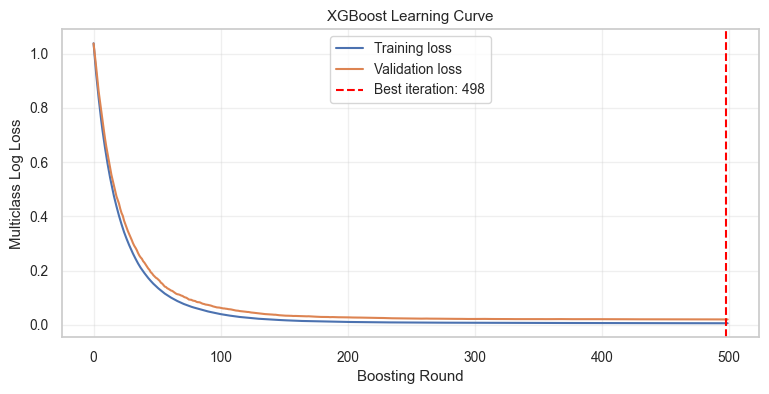

In [15]:
results = xgb_model.evals_result()

train_loss = results["validation_0"]["mlogloss"]
val_loss = results["validation_1"]["mlogloss"]

plt.figure(figsize=(9, 4))

plt.plot(train_loss, label="Training loss")
plt.plot(val_loss, label="Validation loss")

plt.axvline(
    xgb_model.best_iteration,
    color="red",
    linestyle="--",
    label=f"Best iteration: {xgb_model.best_iteration}"
)

plt.xlabel("Boosting Round")
plt.ylabel("Multiclass Log Loss")
plt.title("XGBoost Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Evaluation and comparison

Evaluate all three leakage classes on the held-out configurations. Compare XGBoost with a simpler **ridge-regularized ordinal classifier**.

### 8.1 XGBoost evaluation

Report accuracy, macro F1, the confusion matrix and performance by operating setting.

XGBOOST - UNSEEN CONFIGURATIONS TEST
---------------------------------------------
Accuracy: 98.55%
Macro F1: 0.9857

Classification Report:
                precision    recall  f1-score   support

    No leakage       1.00      1.00      1.00        67
  Weak leakage       0.99      0.97      0.98        70
Severe leakage       0.97      0.99      0.98        70

      accuracy                           0.99       207
     macro avg       0.99      0.99      0.99       207
  weighted avg       0.99      0.99      0.99       207



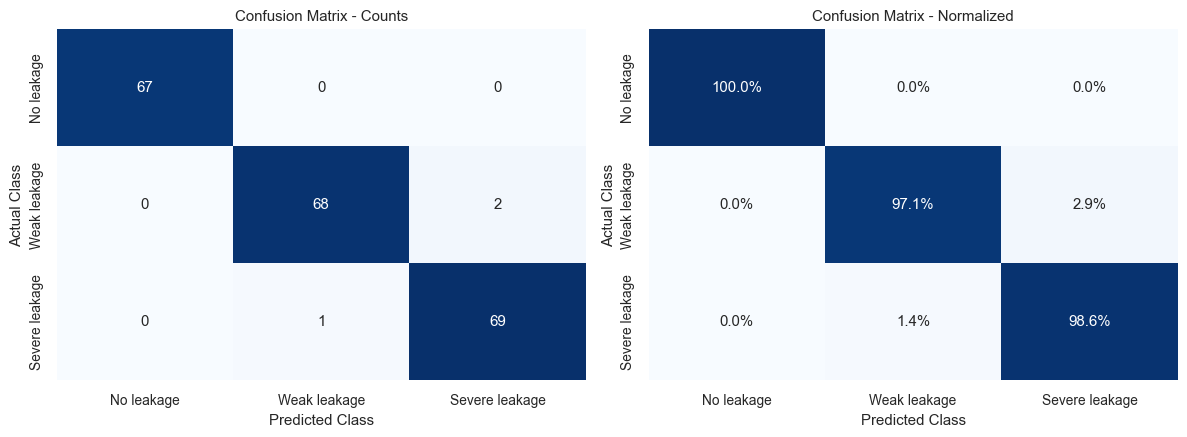

In [16]:
# ==================================================
# OVERALL TEST EVALUATION
# ==================================================

class_names = ["No leakage", "Weak leakage", "Severe leakage"]
class_ids = [0, 1, 2]

y_test_pred = xgb_model.predict(X_test)

print("XGBOOST - UNSEEN CONFIGURATIONS TEST")
print("-" * 45)

print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.2%}")
print(f"Macro F1: {f1_score(y_test, y_test_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrices
cm = confusion_matrix(y_test, y_test_pred, labels=class_ids)
cm_norm = confusion_matrix(
    y_test, y_test_pred,
    labels=class_ids,
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, matrix, title, fmt in zip(
    axes,
    [cm, cm_norm],
    ["Confusion Matrix - Counts", "Confusion Matrix - Normalized"],
    ["d", ".1%"]
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

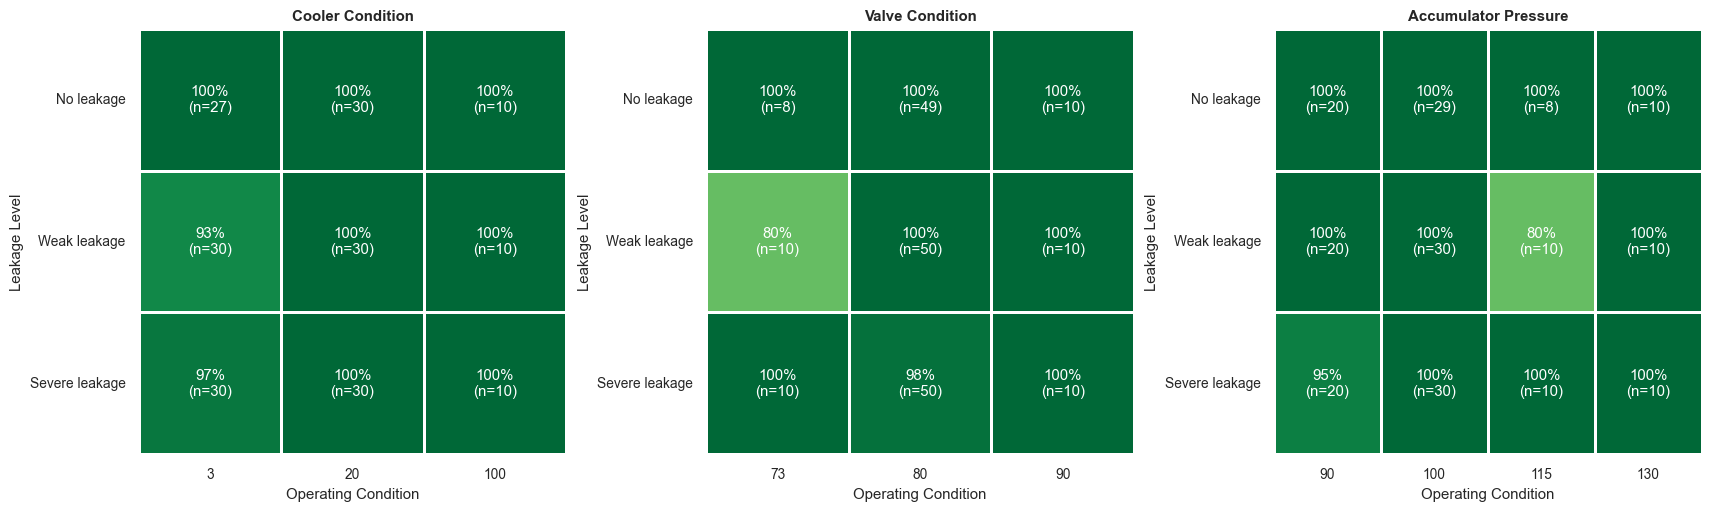

In [17]:
# ==================================================
# PERFORMANCE BY OPERATING CONDITION
# ==================================================

test_results = clean_profile.loc[
    X_test.index,
    condition_cols
].copy()

test_results["Actual"] = y_test.to_numpy()
test_results["Predicted"] = y_test_pred
test_results["Correct"] = (
    test_results["Actual"] == test_results["Predicted"]
)

titles = [
    "Cooler Condition",
    "Valve Condition",
    "Accumulator Pressure"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

for ax, condition, title in zip(
    axes, condition_cols, titles
):

    grouped = (
        test_results
        .groupby([condition, "Actual"])["Correct"]
        .agg(["mean", "size"])
        .reset_index()
    )

    accuracy_matrix = grouped.pivot(
        index="Actual",
        columns=condition,
        values="mean"
    ).reindex(index=[0, 1, 2])

    count_matrix = grouped.pivot(
        index="Actual",
        columns=condition,
        values="size"
    ).reindex(
        index=[0, 1, 2],
        columns=accuracy_matrix.columns
    )

    annotations = accuracy_matrix.copy().astype(object)

    for i in range(accuracy_matrix.shape[0]):
        for j in range(accuracy_matrix.shape[1]):

            acc = accuracy_matrix.iloc[i, j]
            n = count_matrix.iloc[i, j]

            annotations.iloc[i, j] = (
                f"{acc:.0%}\n(n={int(n)})"
                if pd.notna(acc) else ""
            )

    sns.heatmap(
        accuracy_matrix,
        annot=annotations,
        fmt="",
        cmap="RdYlGn",
        vmin=0,
        vmax=1,
        linewidths=1,
        cbar=False,
        ax=ax
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Operating Condition")
    ax.set_ylabel("Leakage Level")
    ax.set_yticklabels(class_names, rotation=0)

plt.show()

### 8.2 Ordinal Logistic Regression (OLR): assumptions

OLR uses one linear severity score with ordered thresholds. The following checks use **training data only**.

| Assumption | Assessment |
|---|---|
| Ordered outcome | **Met:** 0 < 1 < 2 has a meaningful severity order. |
| Independent observations | **Working assumption:** data come from a reputable controlled experiment; consecutive cycles may still be dependent. |
| Proportional odds | **Not verified:** slopes should be comparable across severity thresholds. |
| Linearity of cumulative log-odds | **Not verified:** effects should be linear conditional on other inputs. |
| Full rank and limited collinearity | **Problem:** four constant features and extensive correlation; remove only constants initially. |
| No complete separation | **Violated in training:** the classes are perfectly separable by one linear score. |
| Adequate sample information | **Check:** 1,023 training cycles, balanced labels; repeated configurations reduce independence of information. |
| Model specification | **Not verified:** important interactions or nonlinear terms may be missing. |

**Decision:** Fit ridge-regularized ordinal classification on the **64 nonconstant features**. Ridge helps stabilize coefficients but does not validate proportional odds.

### 8.3 OLR preliminary diagnostics

Check constants, correlations, condition number, approximate threshold effects and complete separation. The exploratory coefficient comparisons are **not** formal proportional-odds tests.

In [18]:
constant_features = X_train.columns[
    X_train.nunique() == 1
].tolist()

print("Number of constant features:", len(constant_features))

for feature in constant_features:
    print(f"{feature}: {X_train[feature].iloc[0]}")

Number of constant features: 4
FS1_min: 0.0
PS2_min: 0.0
PS3_min: 0.0
SE_min: 0.0


1. DATA AND SAMPLE CHECKS
---------------------------------------------
Observations: 1023
Features: 68
Missing values: 0
Non-finite values: 0

Class counts:
pump_leakage
0    343
1    340
2    340
Name: count, dtype: int64

2. CONSTANT FEATURES
---------------------------------------------
Number of constant features: 4
Constant features: ['FS1_min', 'PS2_min', 'PS3_min', 'SE_min']
Remaining features: 64

3. MULTICOLLINEARITY
---------------------------------------------
Matrix rank: 64
Number of features: 64
Condition number: 1.48e+04
Feature pairs with |r| > 0.95: 442

Most correlated pairs:
TS3_mean  TS3_min     0.999994
          TS3_max     0.999993
PS5_mean  PS6_mean    0.999992
TS1_mean  TS1_max     0.999992
          TS1_min     0.999989
TS3_min   TS3_max     0.999984
TS4_mean  TS4_min     0.999983
TS2_mean  TS2_min     0.999981
TS4_mean  TS4_max     0.999980
PS5_max   PS6_max     0.999979
TS1_min   TS1_max     0.999978
TS2_mean  TS2_max     0.999976
PS5_min   PS6_min     0.99

,Feature,Any leakage coefficient,Severe leakage coefficient,Difference,Opposite sign
11,EPS1_max,2.553,5.199,2.645,False
10,EPS1_min,1.783,4.078,2.295,False
45,TS1_std,-1.179,0.898,2.078,True
25,PS2_max,-2.098,-0.110,1.988,False
61,VS1_std,-0.954,0.467,1.421,True
63,VS1_max,-1.211,0.162,1.373,True
8,EPS1_mean,0.606,1.955,1.350,False
9,EPS1_std,1.453,2.574,1.122,False
20,PS1_std,1.549,2.641,1.092,False
62,VS1_min,1.044,0.098,0.946,False



5. NEAR-SEPARATION SCREEN
---------------------------------------------
Threshold Y > 0: training accuracy = 99.90%
Threshold Y > 1: training accuracy = 99.71%

NOTE:
Binary models are regularized screening models.
High accuracy may suggest separation, but does not prove it.
Coefficient differences are not a formal proportional-odds test.


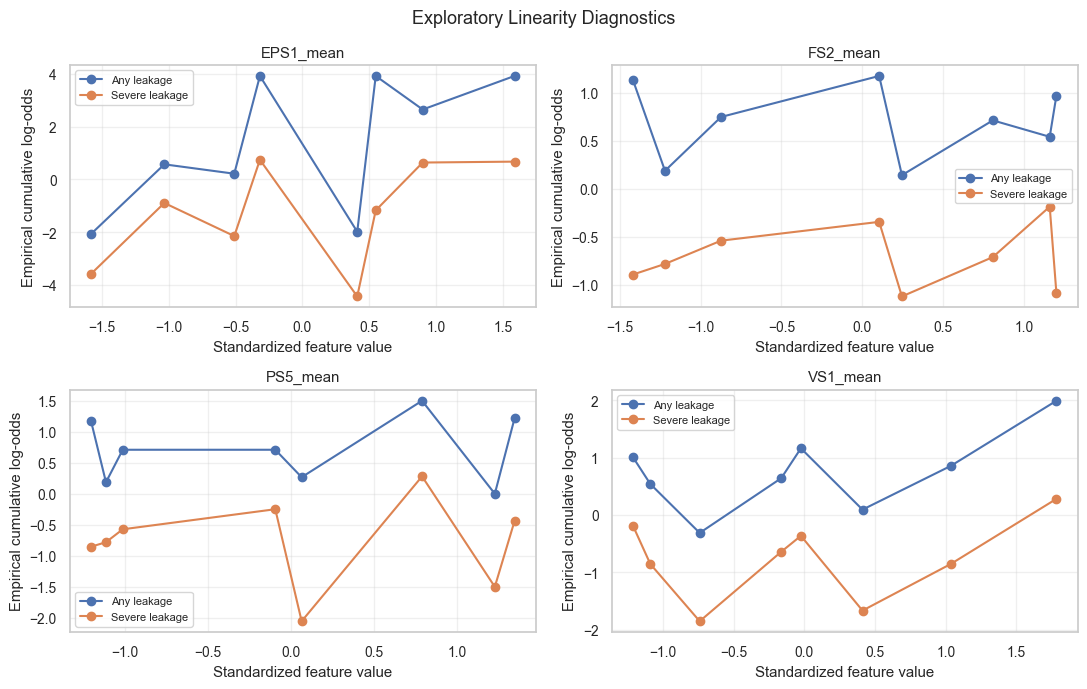

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ==================================================
# OLR - PRELIMINARY DIAGNOSTICS (TRAINING DATA ONLY)
# ==================================================

assert X_train.index.equals(y_train.index)
assert X_train.shape[1] == 68
assert set(y_train.unique()) == {0, 1, 2}

X_numeric = X_train.astype(float)
y_numeric = y_train.astype(int)

# 1. Data quality and sample information
print("1. DATA AND SAMPLE CHECKS")
print("-" * 45)
print("Observations:", len(X_numeric))
print("Features:", X_numeric.shape[1])
print("Missing values:", X_numeric.isna().sum().sum())
print("Non-finite values:", (~np.isfinite(X_numeric.to_numpy())).sum())
print("\nClass counts:")
print(y_numeric.value_counts().sort_index())

# 2. Constant and nearly constant predictors
# 2. Identify and exclude constant predictors
constant_features = X_numeric.columns[
    X_numeric.nunique() == 1
].tolist()

print("\n2. CONSTANT FEATURES")
print("-" * 45)
print("Number of constant features:", len(constant_features))
print("Constant features:", constant_features)

# Remove constants from OLR diagnostics only
X_numeric = X_numeric.drop(columns=constant_features)

# Save feature names for the later OLR model
olr_features = X_numeric.columns.tolist()

print("Remaining features:", len(olr_features))

# Validate data
if not np.isfinite(X_numeric.to_numpy()).all():
    raise ValueError("Missing or non-finite values found.")

# 3. Standardization and matrix diagnostics
scaler_diag = StandardScaler()
X_scaled = pd.DataFrame(
    scaler_diag.fit_transform(X_numeric),
    columns=X_numeric.columns,
    index=X_numeric.index
)

corr = X_scaled.corr().abs()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .loc[lambda x: x > 0.95]
    .sort_values(ascending=False)
)

s = np.linalg.svd(X_scaled.to_numpy(), compute_uv=False)
condition_number = s[0] / s[-1] if s[-1] > 0 else np.inf

print("\n3. MULTICOLLINEARITY")
print("-" * 45)
print("Matrix rank:", np.linalg.matrix_rank(X_scaled))
print("Number of features:", X_scaled.shape[1])
print(f"Condition number: {condition_number:.2e}")
print("Feature pairs with |r| > 0.95:", len(high_corr_pairs))
print("\nMost correlated pairs:")
print(high_corr_pairs.head(15))

# 4. Approximate proportional-odds and separation screening
binary_models = {}

for threshold in [0, 1]:
    binary_y = (y_numeric > threshold).astype(int)

    model = LogisticRegression(
        C=1.0,
        max_iter=3000,
        random_state=42
    )
    model.fit(X_scaled, binary_y)
    binary_models[threshold] = model

coef_0 = binary_models[0].coef_[0]
coef_1 = binary_models[1].coef_[0]

comparison = pd.DataFrame({
    "Feature": X_scaled.columns,
    "Any leakage coefficient": coef_0,
    "Severe leakage coefficient": coef_1
})

comparison["Difference"] = np.abs(coef_0 - coef_1)
comparison["Opposite sign"] = np.sign(coef_0) != np.sign(coef_1)

print("\n4. PROPORTIONAL ODDS - EXPLORATORY SCREEN")
print("-" * 45)
print("Opposite coefficient signs:", comparison["Opposite sign"].sum())
print("\nLargest coefficient differences:")
display(comparison.nlargest(10, "Difference").round(3))

print("\n5. NEAR-SEPARATION SCREEN")
print("-" * 45)

for threshold, model in binary_models.items():
    binary_y = (y_numeric > threshold).astype(int)
    acc = model.score(X_scaled, binary_y)
    print(f"Threshold Y > {threshold}: training accuracy = {acc:.2%}")

print("\nNOTE:")
print("Binary models are regularized screening models.")
print("High accuracy may suggest separation, but does not prove it.")
print("Coefficient differences are not a formal proportional-odds test.")

# 5. Marginal cumulative-logit plots
# These are descriptive checks, not adjusted OLR diagnostics.

plot_features = [
    "EPS1_mean", "FS2_mean", "PS5_mean", "VS1_mean"
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, feature in zip(axes.flat, plot_features):

    temp = pd.DataFrame({
        "x": X_scaled[feature],
        "y": y_numeric
    })

    temp["bin"] = pd.qcut(
        temp["x"], q=8, duplicates="drop"
    )

    for threshold, label in [
        (0, "Any leakage"),
        (1, "Severe leakage")
    ]:
        summary = temp.groupby("bin", observed=True).apply(
            lambda g: pd.Series({
                "x_mean": g["x"].mean(),
                "n": len(g),
                "positive": (g["y"] > threshold).sum()
            }),
            include_groups=False
        )

        # Smoothed empirical log-odds
        log_odds = np.log(
            (summary["positive"] + 0.5) /
            (summary["n"] - summary["positive"] + 0.5)
        )

        ax.plot(
            summary["x_mean"],
            log_odds,
            marker="o",
            label=label
        )

    ax.set_title(feature)
    ax.set_xlabel("Standardized feature value")
    ax.set_ylabel("Empirical cumulative log-odds")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle("Exploratory Linearity Diagnostics")
plt.tight_layout()
plt.show()


In [20]:
from scipy.optimize import linprog
import numpy as np

# Use the 64 standardized, nonconstant features
X_lp = np.column_stack([
    np.ones(len(X_scaled)),
    X_scaled.to_numpy()
])

for threshold in [0, 1]:

    # Convert classes to -1 and +1
    labels = np.where(y_numeric > threshold, 1, -1)

    # Search for coefficients satisfying:
    # labels * (X @ beta) >= 1
    result = linprog(
        c=np.zeros(X_lp.shape[1]),
        A_ub=-(labels[:, None] * X_lp),
        b_ub=-np.ones(len(labels)),
        bounds=[(None, None)] * X_lp.shape[1],
        method="highs"
    )

    print(f"\nThreshold Y > {threshold}")

    if result.success:
        print("Complete linear separation: YES")
    elif result.status == 2:
        print("Complete linear separation: NO")
    else:
        print("Inconclusive:", result.message)


Threshold Y > 0
Complete linear separation: YES

Threshold Y > 1
Complete linear separation: YES


In [21]:
# Standardized, nonconstant training features
X_ordinal_lp = np.column_stack([
    np.ones(len(X_scaled)),
    X_scaled.to_numpy()
])

y_ordinal_lp = y_numeric.to_numpy()

# Unknowns: feature coefficients + second threshold
# First threshold fixed at zero
n_params = X_ordinal_lp.shape[1] + 1

A, b = [], []

for xi, yi in zip(X_ordinal_lp, y_ordinal_lp):
    if yi == 0:
        A.append(np.r_[xi, 0])
        b.append(-1)

    elif yi == 1:
        A.append(np.r_[-xi, 0])
        b.append(-1)

        A.append(np.r_[xi, -1])
        b.append(-1)

    else:
        A.append(np.r_[-xi, 1])
        b.append(-1)

# Require second threshold >= 2
A.append(np.r_[np.zeros(X_ordinal_lp.shape[1]), -1])
b.append(-2)

result = linprog(
    c=np.zeros(n_params),
    A_ub=np.asarray(A),
    b_ub=np.asarray(b),
    bounds=[(None, None)] * n_params,
    method="highs"
)

print("OLR SEPARATION DIAGNOSTIC")
print("-" * 40)

if result.success:
    print("Complete ordinal separation: YES")
elif result.status == 2:
    print("Complete ordinal separation: NO")
else:
    print("Result inconclusive:", result.message)

OLR SEPARATION DIAGNOSTIC
----------------------------------------
Complete ordinal separation: YES


### 8.4 Ridge OLR model

Standardize features using training statistics. Fit `mord.LogisticAT` with several L2 penalties and select `alpha` using validation macro F1. Its all-threshold loss is an ordinal logistic surrogate, not the ordinary cumulative-logit likelihood.

In [22]:
# Ridge regularization OLR model 
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# ==================================================
# 1. PREPARE FEATURES
# ==================================================

# olr_features contains the 64 nonconstant features
# identified in Step 2
assert len(olr_features) == 64

olr_scaler = StandardScaler()

X_train_olr = olr_scaler.fit_transform(
    X_train[olr_features]
)

X_val_olr = olr_scaler.transform(
    X_val[olr_features]
)

# ==================================================
# 2. SELECT RIDGE REGULARIZATION STRENGTH
# ==================================================

alphas = [0.1, 1, 10, 100]

models = {}
results = []

for alpha in alphas:

    model = mord.LogisticAT(
        alpha=alpha,
        max_iter=3000
    )

    # Fresh model trained only on training data
    model.fit(X_train_olr, y_train.to_numpy())

    val_pred = model.predict(X_val_olr)

    models[alpha] = model

    results.append({
        "alpha": alpha,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro F1": f1_score(
            y_val, val_pred, average="macro"
        )
    })

validation_results = pd.DataFrame(results).sort_values(
    ["Macro F1", "Accuracy", "alpha"],
    ascending=[False, False, False]
)

print("VALIDATION RESULTS")
display(validation_results.round(4))

# ==================================================
# 3. SELECT THE BEST MODEL
# ==================================================

best_alpha = validation_results.iloc[0]["alpha"]
olr_model = models[best_alpha]

print(f"\nSelected alpha: {best_alpha}")
print("Number of features:", len(olr_model.coef_))
print("Ordered thresholds:", olr_model.theta_)

assert np.isfinite(olr_model.coef_).all()
assert np.isfinite(olr_model.theta_).all()
assert np.all(np.diff(olr_model.theta_) > 0)

print("Model coefficients and thresholds are finite.")


VALIDATION RESULTS


,alpha,Accuracy,Macro F1
2,10.0,1.0000,1.0000
0,0.1,0.9905,0.9905
1,1.0,0.9857,0.9857
3,100.0,0.9238,0.9234



Selected alpha: 10.0
Number of features: 64
Ordered thresholds: [-1.72000382  2.1376649 ]
Model coefficients and thresholds are finite.


### 8.5 XGBoost vs. Ridge OLR

Evaluate both models on the **same seven unseen test configurations**. One extra correct classification is too little evidence to claim that either model is superior.

MODEL COMPARISON - UNSEEN CONFIGURATIONS


,Model,Accuracy,Macro F1
0,XGBoost,0.9855,0.9857
1,Ridge OLR,0.9903,0.9905



RIDGE OLR - CLASSIFICATION REPORT
                precision    recall  f1-score   support

    No leakage       1.00      1.00      1.00        67
  Weak leakage       0.99      0.99      0.99        70
Severe leakage       0.99      0.99      0.99        70

      accuracy                           0.99       207
     macro avg       0.99      0.99      0.99       207
  weighted avg       0.99      0.99      0.99       207



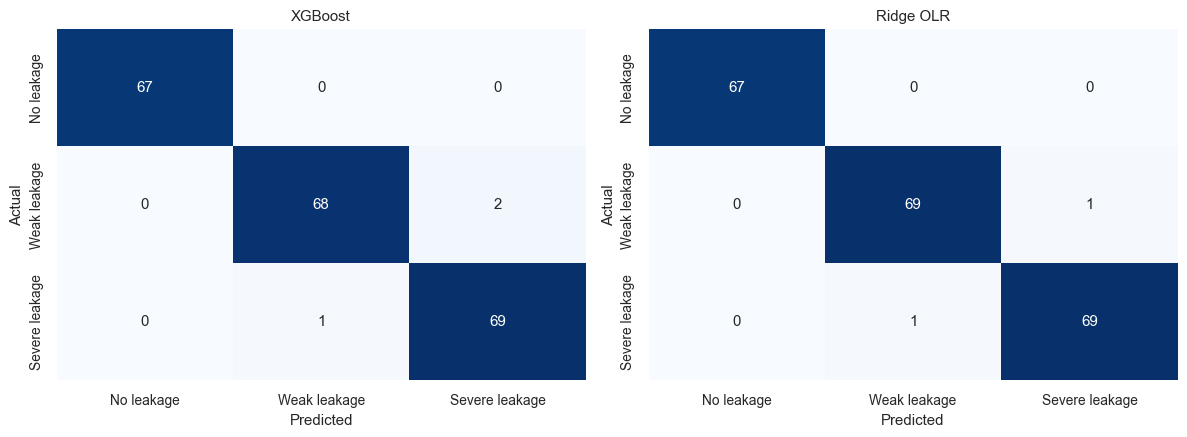

In [23]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==================================================
# 1. TEST PREDICTIONS
# ==================================================

X_test_olr = olr_scaler.transform(
    X_test[olr_features]
)

olr_pred = olr_model.predict(X_test_olr)
xgb_pred = xgb_model.predict(X_test)

# ==================================================
# 2. MODEL COMPARISON
# ==================================================

comparison = pd.DataFrame({
    "Model": ["XGBoost", "Ridge OLR"],
    "Accuracy": [
        accuracy_score(y_test, xgb_pred),
        accuracy_score(y_test, olr_pred)
    ],
    "Macro F1": [
        f1_score(y_test, xgb_pred, average="macro"),
        f1_score(y_test, olr_pred, average="macro")
    ]
})

print("MODEL COMPARISON - UNSEEN CONFIGURATIONS")
display(comparison.round(4))

print("\nRIDGE OLR - CLASSIFICATION REPORT")
print(
    classification_report(
        y_test, olr_pred,
        target_names=[
            "No leakage",
            "Weak leakage",
            "Severe leakage"
        ],
        zero_division=0
    )
)

# ==================================================
# 3. SIDE-BY-SIDE CONFUSION MATRICES
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

class_names = ["No leakage", "Weak leakage", "Severe leakage"]

for ax, predictions, title in zip(
    axes,
    [xgb_pred, olr_pred],
    ["XGBoost", "Ridge OLR"]
):
    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1, 2]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


## 9. Model interpretability

Interpret how XGBoost uses sensor summaries. Gain and SHAP show model behavior, **not physical causation**. Highly correlated inputs can share or compete for credit.

### 9.1 XGBoost feature importance: total gain

Rank engineered features by total split gain. Sum those gains across statistics to summarize importance by physical sensor.

TOP 15 FEATURES


,Feature,Total Gain,Importance (%)
0,SE_mean,7677.36,41.52
1,FS1_mean,4004.14,21.66
2,SE_std,2319.03,12.54
3,EPS1_max,892.82,4.83
4,EPS1_min,839.93,4.54
5,EPS1_mean,506.69,2.74
6,PS1_max,494.80,2.68
7,VS1_max,372.24,2.01
8,PS1_mean,234.72,1.27
9,FS1_std,218.48,1.18


Features used by XGBoost: 62 out of 68


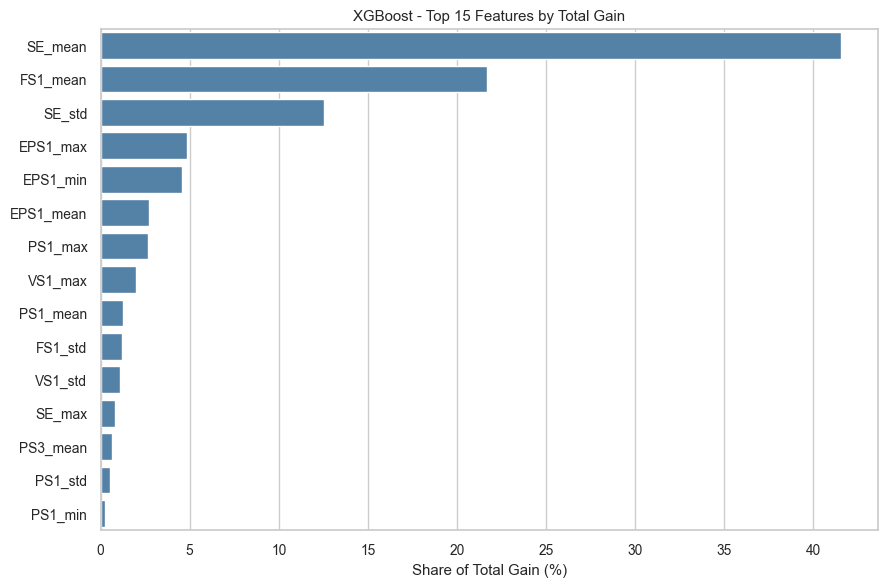

In [24]:
# ==================================================
# XGBOOST - FEATURE IMPORTANCE (TOTAL GAIN)
# ==================================================

booster = xgb_model.get_booster()

# Total gain across all trees
gain_scores = booster.get_score(
    importance_type="total_gain"
)

# Include features not used in any tree (importance = 0)
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Total Gain": [
        gain_scores.get(f, 0.0)
        for f in X_train.columns
    ]
})

# Normalize importance to percentages
total_gain = feature_importance["Total Gain"].sum()

feature_importance["Importance (%)"] = (
    100 * feature_importance["Total Gain"] / total_gain
)

feature_importance = (
    feature_importance
    .sort_values("Importance (%)", ascending=False)
    .reset_index(drop=True)
)

print("TOP 15 FEATURES")
display(feature_importance.head(15).round(2))

print(
    "Features used by XGBoost:",
    (feature_importance["Total Gain"] > 0).sum(),
    "out of", len(feature_importance)
)

# Plot
top_features = feature_importance.head(15)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=top_features,
    x="Importance (%)",
    y="Feature",
    color="steelblue"
)

plt.title("XGBoost - Top 15 Features by Total Gain")
plt.xlabel("Share of Total Gain (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()


SENSOR IMPORTANCE


,Sensor,Importance (%)
0,SE,54.87
1,FS1,22.85
2,EPS1,12.20
3,PS1,4.70
4,VS1,3.37
5,PS3,0.99
6,TS2,0.24
7,TS1,0.18
8,CP,0.16
9,CE,0.12


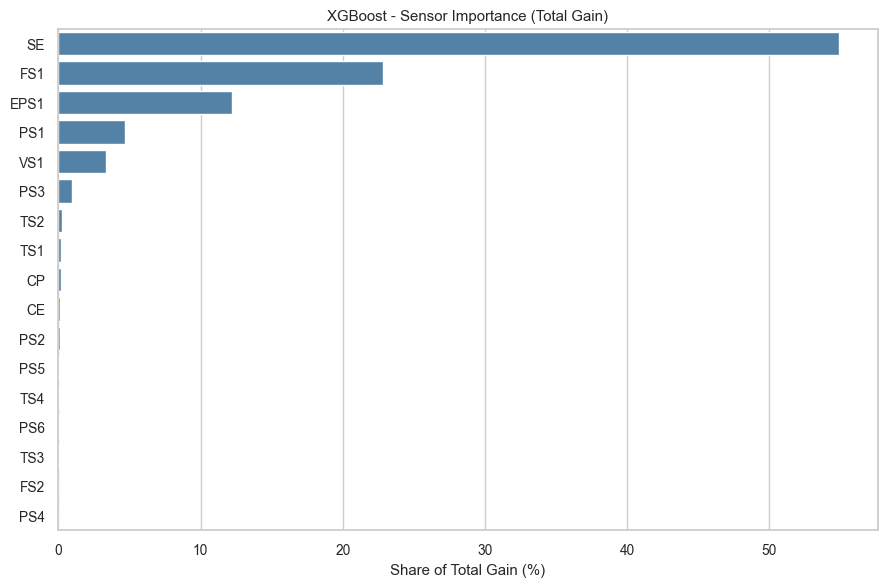

In [25]:
# ==================================================
# XGBOOST - SENSOR-LEVEL FEATURE IMPORTANCE
# ==================================================

sensor_importance = feature_importance.copy()

# Extract sensor name from engineered feature name
sensor_importance["Sensor"] = (
    sensor_importance["Feature"]
    .str.rsplit("_", n=1)
    .str[0]
)

# Aggregate feature importance by sensor
sensor_importance = (
    sensor_importance
    .groupby("Sensor", as_index=False)["Importance (%)"]
    .sum()
    .sort_values("Importance (%)", ascending=False)
    .reset_index(drop=True)
)

print("SENSOR IMPORTANCE")
display(sensor_importance.round(2))

plt.figure(figsize=(9, 6))

sns.barplot(
    data=sensor_importance,
    x="Importance (%)",
    y="Sensor",
    color="steelblue"
)

plt.title("XGBoost - Sensor Importance (Total Gain)")
plt.xlabel("Share of Total Gain (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()


### 9.2 SHAP: global and class-specific importance

Compare mean absolute SHAP values for healthy, weak and severe leakage. SHAP values are expressed in raw class-score units.

SHAP shape: (207, 68, 3)
Expected: (207, 68, 3)

TOP 15 GLOBAL SHAP FEATURES


,Feature,Global,No leakage,Weak leakage,Severe leakage
44,SE_mean,1.256,1.445,0.681,1.643
12,FS1_mean,0.909,1.233,0.604,0.891
45,SE_std,0.453,0.180,0.437,0.741
11,EPS1_max,0.389,0.047,0.312,0.808
23,PS1_max,0.229,0.110,0.194,0.384
20,PS1_mean,0.212,0.198,0.106,0.331
13,FS1_std,0.181,0.249,0.218,0.075
10,EPS1_min,0.176,0.007,0.311,0.210
67,VS1_max,0.156,0.250,0.213,0.004
65,VS1_std,0.133,0.124,0.274,0.000


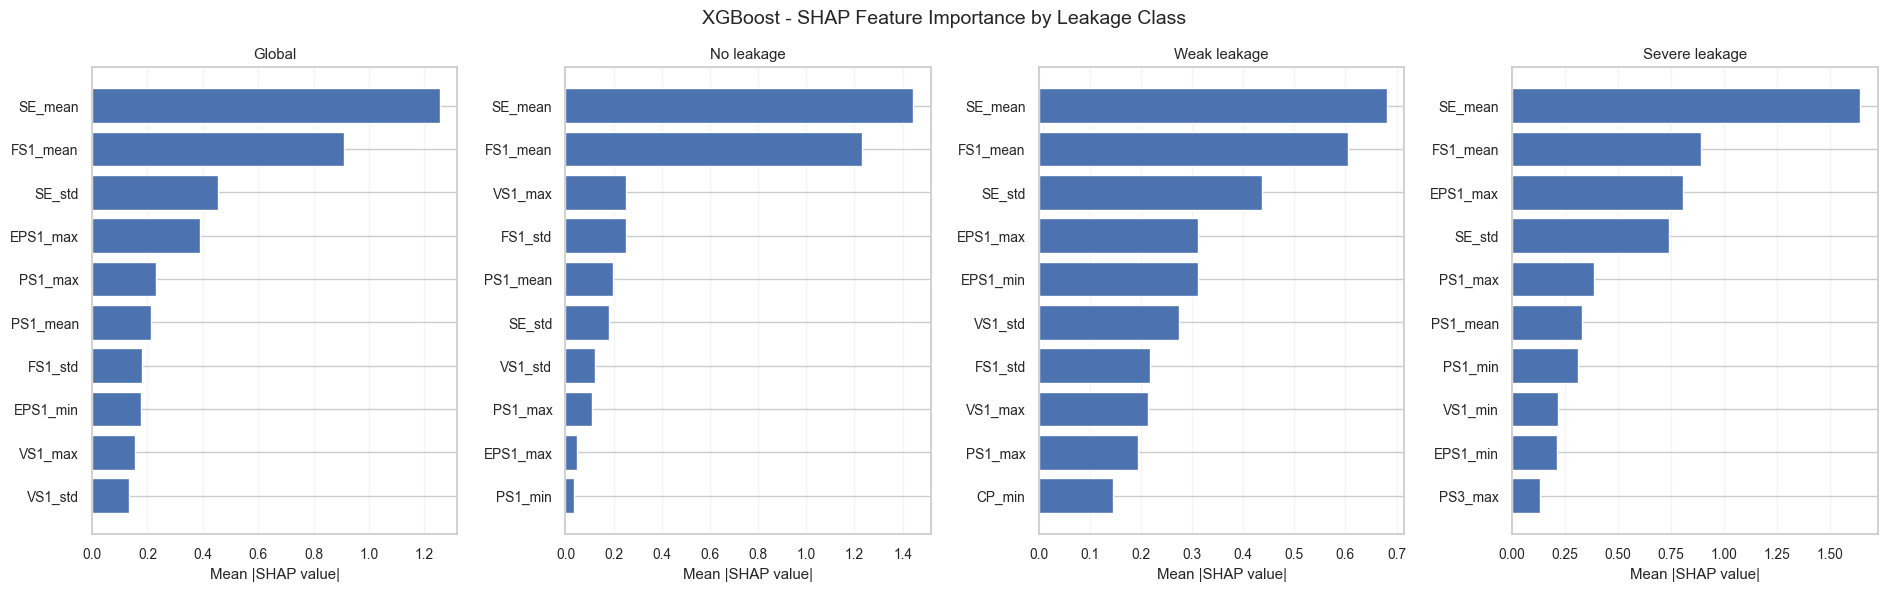

In [26]:
# ==================================================
# XGBOOST - SHAP ANALYSIS
# ==================================================

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)

values = shap_values.values

print("SHAP shape:", values.shape)
print("Expected:", (len(X_test), X_test.shape[1], 3))

assert values.shape == (len(X_test), X_test.shape[1], 3)

class_names = ["No leakage", "Weak leakage", "Severe leakage"]

# Mean absolute SHAP contribution for each feature and class
importance_by_class = np.abs(values).mean(axis=0)

# Global importance averaged across the three classes
global_importance = importance_by_class.mean(axis=1)

shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Global": global_importance,
    **{
        class_names[i]: importance_by_class[:, i]
        for i in range(3)
    }
})

shap_importance = shap_importance.sort_values(
    "Global", ascending=False
)

print("\nTOP 15 GLOBAL SHAP FEATURES")
display(shap_importance.head(15).round(3))

# ==================================================
# GLOBAL AND CLASS-SPECIFIC PLOTS
# ==================================================

fig, axes = plt.subplots(1, 4, figsize=(19, 6))

columns = ["Global"] + class_names

for ax, column in zip(axes, columns):

    top = shap_importance.nlargest(10, column).sort_values(column)

    ax.barh(top["Feature"], top[column])
    ax.set_title(column)
    ax.set_xlabel("Mean |SHAP value|")
    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "XGBoost - SHAP Feature Importance by Leakage Class",
    fontsize=14
)
plt.tight_layout()
plt.show()


### 9.3 SHAP beeswarm plots

Inspect how high and low feature values affect the model's weak- and severe-leakage scores.


SHAP - Weak leakage


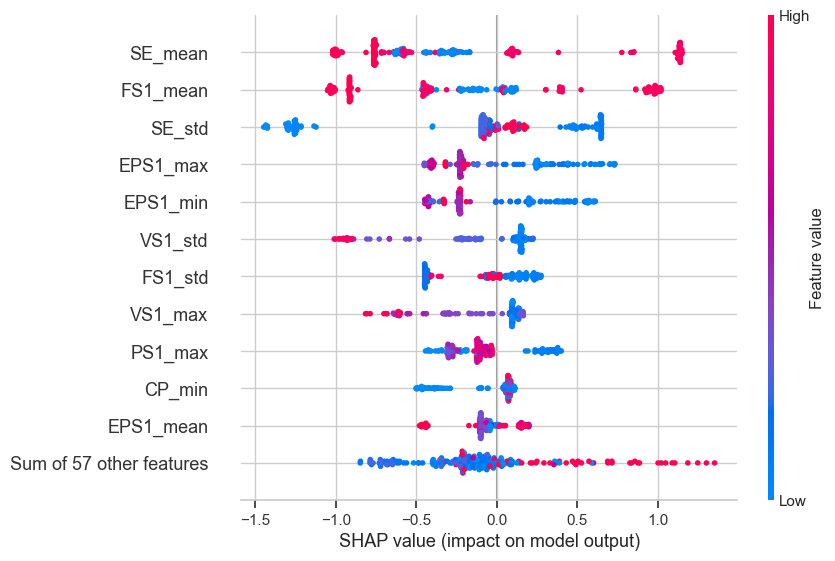


SHAP - Severe leakage


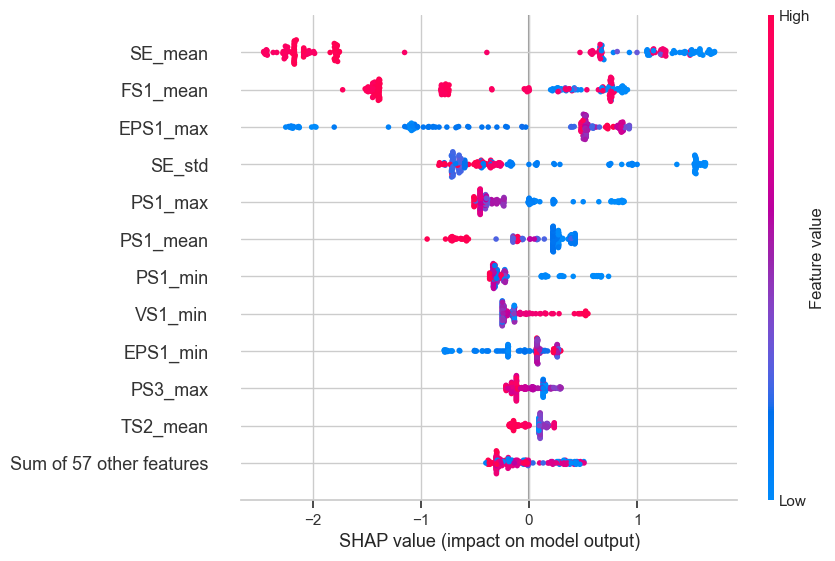

In [27]:

# ==================================================
# SHAP - WEAK AND SEVERE LEAKAGE
# ==================================================

for class_idx, class_name in [
    (1, "Weak leakage"),
    (2, "Severe leakage")
]:
    print(f"\nSHAP - {class_name}")

    shap.plots.beeswarm(
        shap_values[:, :, class_idx],
        max_display=12,
        show=True
    )


### 9.4 SHAP dependence plots

Focus on `SE_mean`, `FS1_mean`, `SE_std` and `EPS1_max` to examine class-specific prediction patterns.

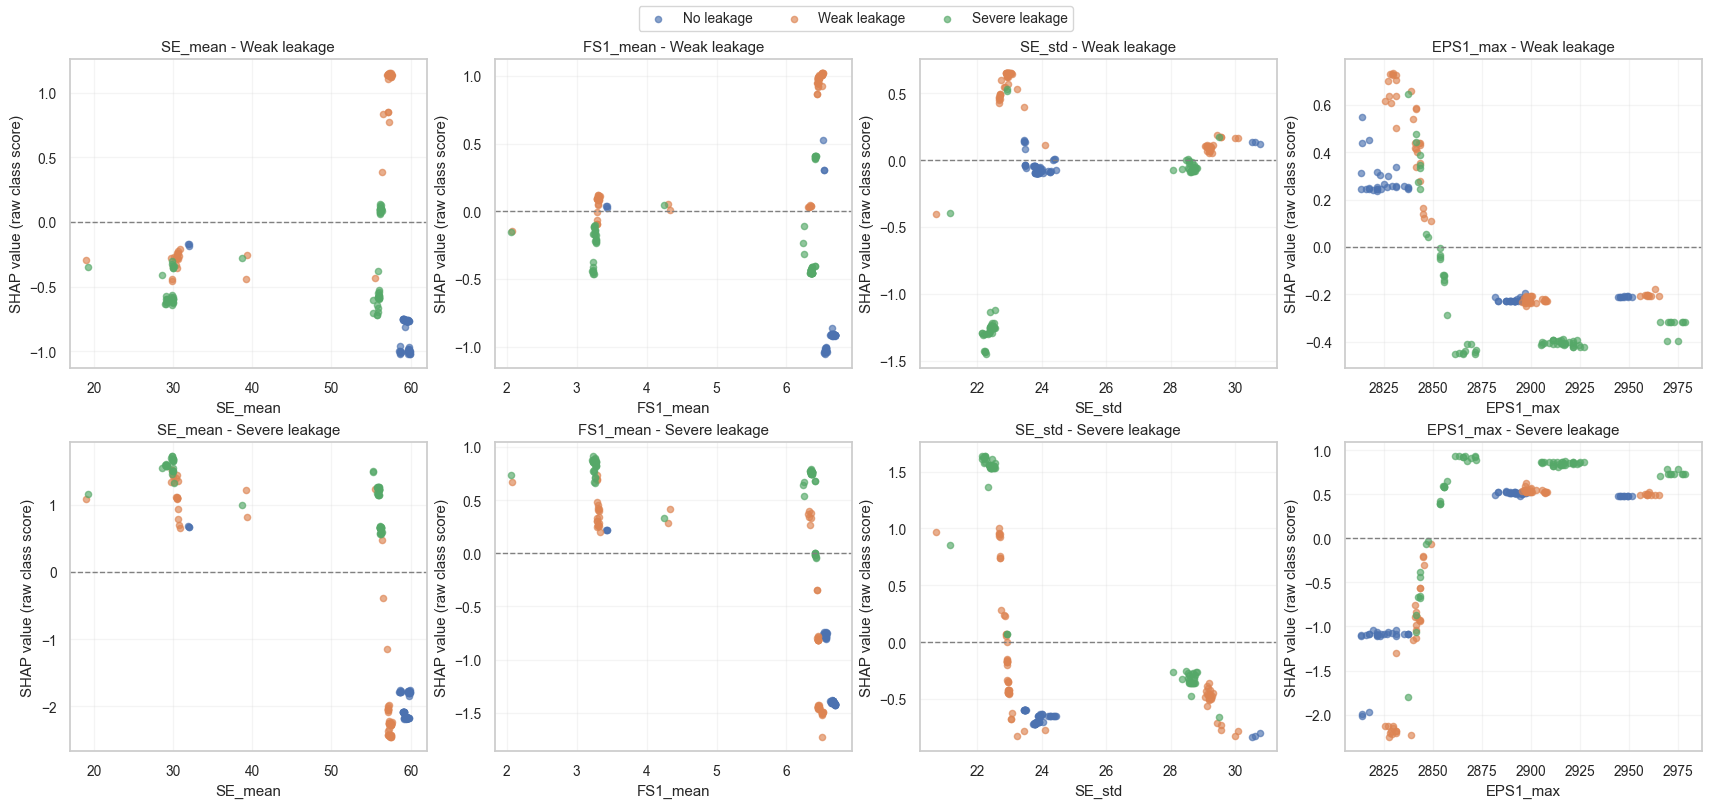

In [28]:
# Four selected features
selected_features = [
    "SE_mean",
    "FS1_mean",
    "SE_std",
    "EPS1_max"
]

classes = {
    1: "Weak leakage",
    2: "Severe leakage"
}

actual_labels = {
    0: "No leakage",
    1: "Weak leakage",
    2: "Severe leakage"
}

y_actual = y_test.to_numpy()

fig, axes = plt.subplots(
    2, 4,
    figsize=(17, 8),
    constrained_layout=True
)

for row, (class_idx, class_name) in enumerate(classes.items()):

    for col, feature in enumerate(selected_features):

        ax = axes[row, col]
        feature_idx = X_test.columns.get_loc(feature)

        x = X_test[feature].to_numpy()
        shap_y = values[:, feature_idx, class_idx]

        for actual_class, label in actual_labels.items():

            mask = y_actual == actual_class

            ax.scatter(
                x[mask],
                shap_y[mask],
                s=20,
                alpha=0.65,
                label=label
            )

        ax.axhline(0, color="gray", linestyle="--", linewidth=1)

        ax.set_title(f"{feature} - {class_name}")
        ax.set_xlabel(feature)
        ax.set_ylabel("SHAP value (raw class score)")
        ax.grid(alpha=0.2)

# Single legend
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="outside upper center",
    ncol=3
)

plt.show()

### 9.5 Derived SE and correlated sensors

`SE` is a derived efficiency factor related to EPS1, FS1 and FS2. Examine correlations before treating their importances as independent evidence.

In [29]:
se_components = [
    "SE_mean",
    "FS1_mean",
    "FS2_mean",
    "EPS1_mean",
    "EPS1_max"
]

display(
    X_train[se_components]
    .corr()
    .round(3)
)

,SE_mean,FS1_mean,FS2_mean,EPS1_mean,EPS1_max
SE_mean,1.000,0.997,0.555,-0.719,0.429
FS1_mean,0.997,1.000,0.614,-0.667,0.496
FS2_mean,0.555,0.614,1.000,0.172,0.972
EPS1_mean,-0.719,-0.667,0.172,1.000,0.299
EPS1_max,0.429,0.496,0.972,0.299,1.000


## 10. Summary and recommendations

- **XGBoost:** 204/207 correct (98.55%); **ridge ordinal model:** 205/207 (99.03%) on unseen configurations. The difference is only one cycle.
- Gain and SHAP emphasize `SE_mean`, `FS1_mean`, `SE_std` and `EPS1_max`. `SE_mean` and `FS1_mean` are strongly correlated.
- These findings concern **current leakage diagnosis** in this test-rig dataset. They do not establish causation or performance on new machines.
- **Next:** Notebook 03 tests XGBoost without the derived SE features and with smaller feature sets.

## 11. Presentation (optional)

Use the grouped test confusion matrices, model comparison and a concise SHAP figure to explain the findings and limitations.